# L'intégrale triangle scalaire à une boucle — trois voies, contrôles et reconnaissance de constantes

Ce carnet étudie le *triangle scalaire* à une boucle, à propagateurs internes sans masse, en dimension 4 euclidienne. Il compare deux quadratures bidimensionnelles et une voie qui intègre analytiquement une variable, puis teste une forme fermée pour une famille de cinématiques isocèles.

Les calculs numériques utilisent des entiers `BigInteger` de la BCL. Les décimaux d'entrée sont représentés exactement ; les divisions et les évaluations de fonctions sont ramenées à une échelle fixe de 112 décimales. Les quadratures et les valeurs transcendantes restent des approximations : l'attestation distingue l'accord des chiffres affichés, les résidus numériques et la preuve d'une identité.

**Prérequis** : bibliothèque standard .NET. La représentation intégrale est introduite au §1.

## 1. Le cadre : définir l'objet avant de le calculer

Le triangle scalaire à une boucle : trois propagateurs scalaires sans masse, un moment externe par sommet. En dimension $D = 4$ euclidienne, avec des moments externes $p_1, p_2, p_3$ tels que $p_1 + p_2 + p_3 = 0$, l'amplitude s'écrit

$$C_0 \;\equiv\; \int \frac{d^4k}{(2\pi)^4}\;\frac{1}{k^2\,(k+p_1)^2\,(k+p_1+p_2)^2}\,.$$

Les invariants cinématiques sont $\alpha = p_1^2$, $\beta = p_2^2$, $\gamma = p_3^2$ : un seul objet dépend de trois nombres — c'est ce qui rend le carnet borné.

**Paramètres de Feynman.** On part de $\frac{1}{ABC} = 2\int_{\text{simplexe}} \frac{dx_2\,dx_3}{(x_1 A + x_2 B + x_3 C)^3}$, avec $x_1 = 1 - x_2 - x_3$, $x_i \geq 0$ :

$$x_1 k^2 + x_2 (k+p_1)^2 + x_3 (k+p_1+p_2)^2 = k^2 + 2k\cdot\big(x_2 p_1 + x_3 (p_1{+}p_2)\big) + x_2\alpha + x_3\gamma\,.$$

En posant $b = x_2 p_1 + x_3 (p_1{+}p_2)$ et en translatant $k \to k - b$, le dénominateur devient $k^2 + \Delta$ avec — en utilisant $p_1\cdot(p_1{+}p_2) = (\alpha+\gamma-\beta)/2$ et $x_1 + x_2 + x_3 = 1$ :

$$\boxed{\;\Delta \;=\; \alpha\, x_1 x_2 \;+\; \gamma\, x_1 x_3 \;+\; \beta\, x_2 x_3\;}$$

**Intégration sur la boucle.** En $D = 4$ : $\int \frac{d^4k}{(2\pi)^4} \frac{1}{(k^2+\Delta)^3} = \frac{1}{(4\pi)^2}\,\frac{\Gamma(1)}{\Gamma(3)}\,\Delta^{-1} = \frac{1}{32\pi^2\,\Delta}$, d'où, en combinant avec le facteur $2! = 2$ :

$$C_0 \;=\; \frac{J}{16\pi^2}\,,\qquad J(\alpha,\beta,\gamma) \;=\; \iint_{\text{simplexe}} \frac{dx_2\,dx_3}{\Delta}\,.$$

Tout le carnet porte sur $J$ ; le facteur $16\pi^2$ est une simple conversion.

**Une convention, un choix.** Le même objet s'écrit aussi avec la base de propagateurs $\{k,\; k+p_1,\; k+p_2\}$, qui fait apparaître $\delta = |p_1 - p_2|^2 = 2(\alpha+\beta)-\gamma$ à la place de $\gamma$ : c'est le *même* objet, à relabelage des moments près. On garde le $\Delta$ canonique ci-dessus.

**Réalisabilité euclidienne.** Un triplet $(\alpha,\beta,\gamma)$ est réalisable si et seulement si $\big|\sqrt{\alpha}-\sqrt{\beta}\big| \leq \sqrt{\gamma} \leq \sqrt{\alpha}+\sqrt{\beta}$ — l'inégalité triangulaire des racines (l'exercice 1 la démontre par Cauchy–Schwarz à partir de $p_3 = -(p_1+p_2)$). Le carnet reste sur ce domaine.

In [1]:
// Socle : décimaux sur BigInteger et quadrature double exponentielle.
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Numerics;
using System.Text;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;

public readonly struct F
{
    public const int Decimales = 112;
    public static readonly BigInteger Echelle = BigInteger.Pow(10, Decimales);
    public BigInteger N { get; }
    public F(BigInteger entierEchelonne) { N = entierEchelonne; }
    public static implicit operator F(int x) => new F(x * Echelle);
    public static F Lire(string texte)
    {
        var p = texte.TrimStart('-', '+').Split('.');
        string fraction = p.Length == 2 ? p[1] : "";
        if (fraction.Length > Decimales) throw new ArgumentException("Entrée trop précise pour l'échelle.");
        var n = BigInteger.Parse(p[0] + fraction, CultureInfo.InvariantCulture);
        return new F((texte.StartsWith("-") ? -n : n) * BigInteger.Pow(10, Decimales - fraction.Length));
    }
    public static F Petit(int k) => new F(BigInteger.Pow(10, Decimales - k));
    public static F Abs(F x) => new F(BigInteger.Abs(x.N));
    public static F operator +(F a, F b) => new F(a.N + b.N);
    public static F operator -(F a, F b) => new F(a.N - b.N);
    public static F operator -(F a) => new F(-a.N);
    public static F operator *(F a, F b) => new F(a.N * b.N / Echelle);
    public static F operator /(F a, F b) => new F(a.N * Echelle / b.N);
    public static F operator *(F a, int b) => new F(a.N * b);
    public static F operator *(int a, F b) => b * a;
    public static F operator /(F a, int b) => new F(a.N / b);
    public static bool operator <(F a, F b) => a.N < b.N;
    public static bool operator >(F a, F b) => a.N > b.N;
    public static bool operator <=(F a, F b) => a.N <= b.N;
    public static bool operator >=(F a, F b) => a.N >= b.N;
}

string Aff(F x, int chiffres, bool scientifique = false)
{
    if (x.N.IsZero) return "0.0";
    var n = BigInteger.Abs(x.N);
    int longueur = n.ToString(CultureInfo.InvariantCulture).Length;
    int exposant = longueur - 1 - F.Decimales;
    string s;
    if (longueur > chiffres)
    {
        var p = BigInteger.Pow(10, longueur - chiffres);
        s = ((n + p / 2) / p).ToString(CultureInfo.InvariantCulture);
        if (s.Length > chiffres) exposant++;
    }
    else s = n.ToString(CultureInfo.InvariantCulture);
    s = s.TrimEnd('0');
    string signe = x.N.Sign < 0 ? "-" : "";
    if (scientifique || exposant < -4 || exposant >= chiffres)
        return signe + s[0] + (s.Length > 1 ? "." + s.Substring(1) : ".0") + "e" + exposant.ToString(CultureInfo.InvariantCulture);
    int position = exposant + 1;
    if (position <= 0) return signe + "0." + new string('0', -position) + s;
    if (position >= s.Length) return signe + s.PadRight(position, '0') + ".0";
    return signe + s.Insert(position, ".");
}

F Racine(F x)
{
    if (x < 0) throw new ArgumentOutOfRangeException(nameof(x));
    if (x.N.IsZero) return 0;
    var n = x.N * F.Echelle;
    var a = BigInteger.One << ((n.ToByteArray().Length * 8 + 1) / 2);
    for (;;)
    {
        var b = (a + n / a) >> 1;
        if (b >= a) return new F(a);
        a = b;
    }
}

F ArcTangenteInverse(int q)
{
    F p = (F)1 / q, s = 0;
    for (int k = 0; !p.N.IsZero; k++, p = -p / (q * q)) s += p / (2 * k + 1);
    return s;
}
F Pi = 16 * ArcTangenteInverse(5) - 4 * ArcTangenteInverse(239);

F Exponentielle(F x)
{
    if (x > 0) return 1 / Exponentielle(-x);
    int divisions = 0;
    while (x < -F.Lire("0.125")) { x /= 2; divisions++; }
    F somme = 1, terme = 1;
    for (int k = 1; ; k++)
    {
        terme = terme * x / k;
        if (terme.N.IsZero) break;
        somme += terme;
    }
    for (int i = 0; i < divisions; i++) somme *= somme;
    return somme;
}

F LogAtanh(F x)
{
    F y = (x - 1) / (x + 1), y2 = y * y, p = y, s = 0;
    for (int k = 1; !p.N.IsZero; k += 2, p *= y2) s += p / k;
    return 2 * s;
}
F ln2 = LogAtanh(2);
F Log(F x)
{
    if (x <= 0) throw new ArgumentOutOfRangeException(nameof(x));
    int k = 0;
    while (x >= 2) { x /= 2; k++; }
    while (x < 1) { x *= 2; k--; }
    return LogAtanh(x) + k * ln2;
}
F Sin(F x)
{
    F x2 = x * x, t = x, s = x;
    for (int k = 1; ; k++)
    {
        t = -t * x2 / ((2 * k) * (2 * k + 1));
        if (t.N.IsZero) return s;
        s += t;
    }
}
F Cos(F x) => Sin(Pi / 2 - x);

bool triangle_reel(F alpha, F beta, F gamma)
{
    if (alpha < 0 || beta < 0 || gamma < 0) return false;
    // Équivalent à |gamma - alpha - beta| <= 2 sqrt(alpha beta), sans arrondir.
    BigInteger d = gamma.N - alpha.N - beta.N;
    return d * d <= 4 * alpha.N * beta.N;
}

(F x, F reste, F poids)[] TanhSinh(int subdivisions)
{
    // x(t) = 1/(1 + exp(-pi sinh(t))). On conserve séparément 1-x(t).
    var noeuds = new List<(F x, F reste, F poids)>();
    F pas = (F)1 / subdivisions;
    F croissance = Exponentielle(pas), e = 1;
    F seuil = F.Petit(55);
    for (int k = 0; ; k++, e *= croissance)
    {
        F inverse = 1 / e;
        F q = Exponentielle(-Pi * (e - inverse) / 2);
        if (q < seuil) break;
        F petit = q / (1 + q), grand = 1 - petit;
        F poids = Pi * (e + inverse) / 2 * petit * grand / subdivisions;
        noeuds.Add((petit, grand, poids));
        if (k != 0) noeuds.Add((grand, petit, poids));
    }
    return noeuds.ToArray();
}
var regle1D = TanhSinh(64);
var regle2D = TanhSinh(128);
F Integrer(Func<F, F, F> f, bool dense = false)
{
    BigInteger somme = BigInteger.Zero;
    foreach (var (x, reste, poids) in dense ? regle2D : regle1D)
        somme += poids.N * f(x, reste).N;
    return new F(somme / F.Echelle);
}

var mesures = new Dictionary<string, F>();
void Mesurer(string groupe, F ecart)
{
    if (!mesures.TryGetValue(groupe, out var plafond) || ecart > plafond) mesures[groupe] = ecart;
}
void Valeur(string groupe, string titre, F calcule, string attendu, int chiffres)
{
    F reference = F.Lire(attendu), delta = F.Abs(calcule - reference);
    Mesurer(groupe, delta);
    string valeur = Aff(calcule, chiffres), cible = Aff(reference, chiffres);
    Console.WriteLine($"{titre} : {valeur} ; référence affichée {cible} ; écart à cette décimale {Aff(delta, 3, true)} ; {(valeur == cible ? "CONFORME" : "ÉCART")}");
    if (valeur != cible) throw new Exception($"Chiffres de référence non retrouvés : {titre}");
}
void Residu(string groupe, string titre, F calcule, F reference, F tolerance)
{
    F delta = F.Abs(calcule - reference);
    Mesurer(groupe, delta);
    Console.WriteLine($"{titre} : calculé {Aff(calcule, 3, true)} ; référence {Aff(reference, 3, true)} ; écart {Aff(delta, 3, true)} ; {(delta <= tolerance ? "CONFORME à la tolérance" : "ÉCART")}");
    if (delta > tolerance) throw new Exception($"Résidu hors tolérance : {titre}");
}

F test = Integrer((x, _) => x * x), attenduTest = (F)1 / 3;
Residu("Socle — contrôle polynomial", "Intégrale de x² moins 1/3", test - attenduTest, 0, F.Petit(50));
Console.WriteLine($"Échelle du calcul : {F.Decimales} décimales ; référence Python : 30 chiffres de travail, puis 40 au §6.");

Intégrale de x² moins 1/3 : calculé -2.1e-55 ; référence 0.0 ; écart 2.1e-55 ; CONFORME à la tolérance


Échelle du calcul : 112 décimales ; référence Python : 30 chiffres de travail, puis 40 au §6.


In [2]:
// Les quatre cinématiques du carnet (+ contrôle de réalisabilité).
var CINEMATIQUES = new (F a, F b, F g)[]
{
    (1, 1, 3), (1, 1, 2), (1, 2, F.Lire("2.5")), (1, 1, F.Lire("3.9"))
};
string Entree(F x)
{
    string s = Aff(x, 12);
    return s.EndsWith(".0", StringComparison.Ordinal) ? s.Substring(0, s.Length - 2) : s;
}
string[] racinesA = { "1.0", "1.0", "1.0", "1.0" };
string[] racinesB = { "1.0", "1.0", "1.41421", "1.0" };
string[] racinesG = { "1.73205", "1.41421", "1.58114", "1.97484" };
Console.WriteLine("Les quatre cinématiques :");
for (int i = 0; i < CINEMATIQUES.Length; i++)
{
    var (a, b, g) = CINEMATIQUES[i];
    var ra = Racine(a); var rb = Racine(b); var rg = Racine(g);
    bool reel = triangle_reel(a, b, g);
    Console.WriteLine($"  (alpha, beta, gamma) = ({Entree(a)}, {Entree(b)}, {Entree(g)})   racines ({Aff(ra, 6)}, {Aff(rb, 6)}, {Aff(rg, 6)})   réel : {(reel ? "oui" : "NON")}");
    Valeur("§1 — racines", "Racine de alpha", ra, racinesA[i], 6);
    Valeur("§1 — racines", "Racine de bêta", rb, racinesB[i], 6);
    Valeur("§1 — racines", "Racine de gamma", rg, racinesG[i], 6);
    if (!reel) throw new Exception("Cinématique attendue réalisable.");
}

Les quatre cinématiques :


  (alpha, beta, gamma) = (1, 1, 3)   racines (1.0, 1.0, 1.73205)   réel : oui


Racine de alpha : 1.0 ; référence affichée 1.0 ; écart à cette décimale 0.0 ; CONFORME


Racine de bêta : 1.0 ; référence affichée 1.0 ; écart à cette décimale 0.0 ; CONFORME


Racine de gamma : 1.73205 ; référence affichée 1.73205 ; écart à cette décimale 8.08e-7 ; CONFORME


  (alpha, beta, gamma) = (1, 1, 2)   racines (1.0, 1.0, 1.41421)   réel : oui


... (7 outputs left out)

  (alpha, beta, gamma) = (1, 1, 3.9)   racines (1.0, 1.0, 1.97484)   réel : oui


Racine de alpha : 1.0 ; référence affichée 1.0 ; écart à cette décimale 0.0 ; CONFORME


Racine de bêta : 1.0 ; référence affichée 1.0 ; écart à cette décimale 0.0 ; CONFORME


Racine de gamma : 1.97484 ; référence affichée 1.97484 ; écart à cette décimale 1.77e-6 ; CONFORME


**Lecture.** Les quatre cinématiques sont toutes déclarées `réel : oui`, et les douze racines affichées sont `CONFORME` à six décimales : par exemple $\sqrt{3}$ sort à `1.73205` avec un écart de 8,08e-7, qui reste le reliquat de l'arrondi d'affichage et non une erreur de calcul. La cinématique $(1, 1, 3{,}9)$ donne $\sqrt{\gamma} = 1{,}97484$ : elle approche la frontière sans la franchir.

(1, 2, 2.5) — grille 401 × 401 ; écart maximal de Δ à la référence entière : 2.78E-016 (attendu : ≤ 1.00E-014) ; plage log10(Δ borné) : [-12, -0.19033299] (attendue : [-12, -0.19033299]) ; CONFORME


(1, 1, 3.9) — grille 401 × 401 ; écart maximal de Δ à la référence entière : 5.00E-016 (attendu : ≤ 1.00E-014) ; plage log10(Δ borné) : [-12, -0.010995384] (attendue : [-12, -0.010995384]) ; CONFORME


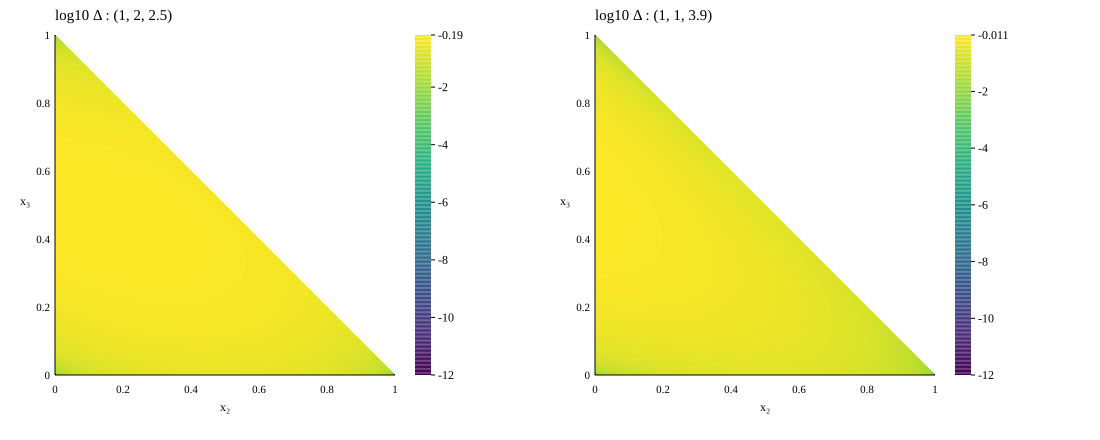

In [3]:
// Illustration 1 — Où vit l'intégrande ? Delta sur le simplexe (x2, x3), x1 = 1 - x2 - x3.
public class Graphique
{
    public string Svg { get; }
    public Graphique(string svg) { Svg = svg; }
}

void AfficherDelta()
{
    const int n = 401, m = n - 1;
    const double plancher = 1e-12, tolerance = 1e-14;
    var grille = Enumerable.Range(0, n).Select(i => i * (1.0 / m)).ToArray();
    // Invariants en dixièmes : ils servent aussi au contrôle indépendant en entiers.
    var panneaux = new (int a10, int b10, int g10)[] { (10, 20, 25), (10, 10, 39) };
    // Viridis approchée par interpolation RGB ; normalisation linéaire par panneau, comme en Python.
    var ancres = new (int r, int v, int b)[] {
        (68, 1, 84), (71, 45, 123), (59, 82, 139), (44, 114, 142),
        (33, 145, 140), (40, 174, 128), (94, 201, 98), (173, 220, 48), (253, 231, 37)
    };
    string Couleur(int k)
    {
        double pos = k * (ancres.Length - 1) / 255.0;
        int i = Math.Min((int)pos, ancres.Length - 2);
        double t = pos - i;
        int Melanger(int p, int q) => (int)Math.Round(p + t * (q - p));
        var (r0, v0, b0) = ancres[i];
        var (r1, v1, b1) = ancres[i + 1];
        return FormattableString.Invariant($"#{Melanger(r0, r1):X2}{Melanger(v0, v1):X2}{Melanger(b0, b1):X2}");
    }
    var palette = Enumerable.Range(0, 256).Select(Couleur).ToArray();
    var svg = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='1100' height='440' viewBox='0 0 1100 440' role='img' aria-label='Logarithme décimal de Delta sur le simplexe, pour deux cinématiques'><rect width='1100' height='440' fill='white'/>");
    for (int p = 0; p < panneaux.Length; p++)
    {
        var (a10, b10, g10) = panneaux[p];
        double a = a10 / 10.0, b = b10 / 10.0, g = g10 / 10.0;
        var valeurs = new double[n, n];
        double min = double.PositiveInfinity, max = double.NegativeInfinity, ecartMax = 0;
        long numerateurMax = 0;
        const double denominateur = 10.0 * m * m;
        for (int j = 0; j < n; j++)
        for (int i = 0; i < n; i++)
        {
            double x2 = grille[i], x3 = grille[j];
            double x1 = 1.0 - x2 - x3;
            double delta = a * x1 * x2 + g * x1 * x3 + b * x2 * x3;
            if (x2 + x3 > 1.0)
            {
                valeurs[j, i] = double.NaN;
                continue;
            }
            // Référence exacte avant division : forme polynomiale développée en i et j.
            long numerateur = m * (a10 * i + g10 * j) - a10 * i * i - g10 * j * j
                + (b10 - a10 - g10) * i * j;
            double ecart = Math.Abs(delta - numerateur / denominateur);
            if (!(ecart <= tolerance) || numerateur < 0)
                throw new Exception($"Delta non conforme au nœud ({i}, {j}).");
            ecartMax = Math.Max(ecartMax, ecart);
            numerateurMax = Math.Max(numerateurMax, numerateur);
            double valeur = Math.Log10(Math.Max(delta, plancher));
            valeurs[j, i] = valeur;
            min = Math.Min(min, valeur);
            max = Math.Max(max, valeur);
        }
        double minAttendu = Math.Log10(plancher);
        double maxAttendu = Math.Log10(numerateurMax / denominateur);
        if (!(Math.Abs(min - minAttendu) <= tolerance && Math.Abs(max - maxAttendu) <= tolerance)
            || valeurs[0, 0] != minAttendu || valeurs[0, m] != minAttendu || valeurs[m, 0] != minAttendu
            || !double.IsNaN(valeurs[m, m]))
            throw new Exception("Échelle, sommets ou masque du simplexe non conformes.");
        Console.WriteLine(FormattableString.Invariant($"({a}, {b}, {g}) — grille {n} × {n} ; écart maximal de Δ à la référence entière : {ecartMax:E2} (attendu : ≤ {tolerance:E2}) ; plage log10(Δ borné) : [{min:G8}, {max:G8}] (attendue : [{minAttendu:G8}, {maxAttendu:G8}]) ; CONFORME"));

        int Indice(double valeur) => double.IsNaN(valeur) ? -1
            : Math.Clamp((int)(256 * (valeur - min) / (max - min)), 0, 255);
        // Un trait par suite de pixels de même couleur ; chaque pixel est centré sur son nœud.
        var chemins = Enumerable.Range(0, 256).Select(_ => new StringBuilder()).ToArray();
        for (int j = 0; j < n; j++)
        {
            for (int debut = 0; debut < n; )
            {
                int k = Indice(valeurs[j, debut]), fin = debut + 1;
                while (fin < n && Indice(valeurs[j, fin]) == k) fin++;
                if (k >= 0) chemins[k].AppendFormat(CultureInfo.InvariantCulture, "M{0} {1}h{2}", debut, m - j, fin - debut);
                debut = fin;
            }
        }
        int x = 55 + 540 * p;
        svg.AppendFormat(CultureInfo.InvariantCulture, "<text x='{0}' y='20' font-size='15'>log10 Δ : ({1}, {2}, {3})</text><svg x='{0}' y='35' width='340' height='340' viewBox='-0.5 -0.5 401 401'><g transform='translate(-0.5 0)' fill='none' shape-rendering='crispEdges'>", x, a, b, g);
        for (int k = 0; k < palette.Length; k++)
            if (chemins[k].Length > 0)
                svg.AppendFormat(CultureInfo.InvariantCulture, "<path stroke='{0}' d='{1}'/>", palette[k], chemins[k]);
        svg.Append("</g></svg>");
        svg.AppendFormat(CultureInfo.InvariantCulture, "<path d='M{0} 375h340 M{0} 375v-340' stroke='black' fill='none'/><text x='{1}' y='411'>x₂</text><text x='{2}' y='205'>x₃</text>", x, x + 165, x - 35);
        for (int i = 0; i <= 5; i++)
        {
            double t = i / 5.0;
            svg.AppendFormat(CultureInfo.InvariantCulture, "<text x='{0:F1}' y='393' text-anchor='middle' font-size='11'>{1:0.#}</text><text x='{2}' y='{3:F1}' text-anchor='end' font-size='11'>{1:0.#}</text>", x + 340 * t, t, x - 5, 379 - 340 * t);
        }
        for (int k = 0; k < palette.Length; k++)
            svg.AppendFormat(CultureInfo.InvariantCulture, "<rect x='{0}' y='{1:F3}' width='16' height='1.34' fill='{2}'/>", x + 360, 375 - (k + 1) * 340.0 / 256, palette[k]);
        void Graduation(double v)
        {
            double y = 375 - 340 * (v - min) / (max - min);
            svg.AppendFormat(CultureInfo.InvariantCulture, "<path d='M{0} {1:F2}h4' stroke='black'/><text x='{2}' y='{3:F2}' font-size='12'>{4:0.###}</text>", x + 376, y, x + 383, y + 4, v);
        }
        Graduation(min);
        for (int v = -10; v <= -2; v += 2) Graduation(v);
        Graduation(max);
    }
    svg.Append("</svg>");
    // Publier le document vectoriel brut comme sortie SVG native du carnet.
    Microsoft.DotNet.Interactive.Formatting.Formatter.Register<Graphique>((graphique, writer) => writer.Write(graphique.Svg), "image/svg+xml");
    display(new Graphique(svg.ToString()), "image/svg+xml");
}

AfficherDelta();

**Lecture.** $\Delta$ ne s'annule qu'aux **trois sommets** du simplexe — sur une arête, un seul $x_i$ est nul et le produit des deux autres reste strictement positif, sur les bords comme à l'intérieur : l'intégrande $1/\Delta$ diverge aux coins mais reste intégrable — la structure typique d'une intégrale de Feynman convergente. Le panneau de droite, $(\alpha,\beta,\gamma) = (1, 1, 3.9)$, est proche de la dégénérescence ($\sqrt{3.9} \approx 1{,}975$, tout près de $\sqrt{\alpha}+\sqrt{\beta} = 2$) : la vallée se resserre et la quadrature devient plus difficile — c'est le **point de stress** du carnet, qui mettra les trois voies à l'épreuve au §5.

## 2. Voie A — quadrature 2D sur le simplexe

Pour chaque $x_2$ dans l’intervalle unité, la quadrature intérieure en $x_3$ va de zéro à $1-x_2$. Dans la référence Python, `mpmath.quad` refuse une fonction en guise d'extrémité : aucun point de l'intégrande n'est évalué avant cette erreur. La parade consiste à imbriquer deux quadratures, la seconde recevant une borne numérique calculée pour chaque $x_2$.

Le port reprend cette imbrication et la famille de quadrature par défaut de `mpmath`, **tanh–sinh**. Il construit lui-même les nœuds et les poids avec la BCL : son pas, sa troncature et ses arrondis ne reproduisent pas l'adaptation interne de `mpmath`.

In [4]:
// Voie A — quadrature tanh–sinh imbriquée sur le simplexe.
F J_A(F alpha, F beta, F gamma)
{
    return Integrer((x2, borne) => Integrer((t, resteT) =>
    {
        // x3 = borne * t, x1 = borne * resteT. Le jacobien borne
        // se simplifie avec le facteur borne commun aux trois termes de Delta.
        return 1 / (alpha * x2 * resteT + gamma * borne * resteT * t + beta * x2 * t);
    }, true), true);
}
var (aDemo, bDemo, gDemo) = CINEMATIQUES[2];
F JA_demo = J_A(aDemo, bDemo, gDemo);
F C0_demo = JA_demo / (16 * Pi * Pi);
Valeur("§2 — J_A", "J_A(1, 2, 2.5)", JA_demo, "1.3427652838373602509494", 25);
Valeur("§2 — C0", "C0 = J/(16 pi²)", C0_demo, "0.00850316049452", 12);

J_A(1, 2, 2.5) : 1.3427652838373602509494 ; référence affichée 1.3427652838373602509494 ; écart à cette décimale 2.15e-26 ; CONFORME


C0 = J/(16 pi²) : 0.00850316049452 ; référence affichée 0.00850316049452 ; écart à cette décimale 4.94e-15 ; CONFORME


**Lecture.** La cellule compare le résultat de la voie A à la décimale affichée par la référence Python, puis répète le contrôle pour $C_0=J/(16\pi^2)$. L'écart affiché est mesuré contre une référence déjà arrondie, et non contre la valeur mathématique exacte. La voie A sert de point de comparaison pour B et C.

## 3. Voie B — substitution homogène : le simplexe devient un rectangle

On exploite l'homogénéité du simplexe : posons $x_2 = uv$, $x_3 = u(1-v)$ avec $(u,v) \in [0,1]^2$ (jacobien $u$ ; $x_1 = 1-u$ ; la variable $v$ décrit le *rapport* $x_3/x_2$). Alors

$$\Delta = u\,\Big[(1-u)\big(\alpha v + \gamma(1-v)\big) + \beta\, u\, v(1-v)\Big]
\quad\Longrightarrow\quad
J = \iint_{[0,1]^2} \frac{du\,dv}{(1-u)\big(\alpha v + \gamma(1-v)\big) + \beta\,u\,v(1-v)}\,.$$

Deux bénéfices numériques : le domaine devient un **rectangle** — la quadrature 2D redevient utilisable, sans bornes callables — et le facteur $(1-u)$ refactorise la singularité du coin $x_1 \to 0$ du côté « $u$ », laissant une intégrande lisse.

In [5]:
// Voie B — quadrature tanh–sinh sur le rectangle (u, v).
F Denominateur(F u, F resteU, F v, F resteV, F alpha, F beta, F gamma)
    => resteU * (alpha * v + gamma * resteV) + beta * u * v * resteV;
F J_B(F alpha, F beta, F gamma)
    => Integrer((u, resteU) => Integrer((v, resteV) =>
        1 / Denominateur(u, resteU, v, resteV, alpha, beta, gamma), true), true);
F JB_demo = J_B(aDemo, bDemo, gDemo);
Valeur("§3 — J_B", "J_B(1, 2, 2.5)", JB_demo, "1.3427652838373602509494", 25);
Residu("§3 — résidu A/B", "|J_A - J_B|", F.Abs(JA_demo - JB_demo), 0, F.Petit(30));

J_B(1, 2, 2.5) : 1.3427652838373602509494 ; référence affichée 1.3427652838373602509494 ; écart à cette décimale 2.15e-26 ; CONFORME


|J_A - J_B| : calculé 2.36e-43 ; référence 0.0 ; écart 2.36e-43 ; CONFORME à la tolérance


**Lecture.** La voie B retrouve les mêmes chiffres que la voie A tout en ramenant le domaine d'intégration à un rectangle, avec des bornes fixes. La leçon est générale : **changer de coordonnées avant de régler l'algorithme** peut simplifier la quadrature sans changer l'intégrale.

## 4. Voie C — intégrer une variable à la main : plus qu'une quadrature 1D

Fixons $u$ (cadre de la voie B). L'intégrande en $v$ a une **quadratique** au dénominateur :

$$D(u,v) = C + B v - A v^2,\qquad A = \beta\, u,\quad B = (1-u)(\alpha - \gamma) + \beta\, u,\quad C = \gamma\,(1-u).$$

Comme $D > 0$ sur $[0,1]$, les racines $r_\pm = \frac{B \pm \sqrt{B^2 + 4AC}}{2A}$ encadrent l'intervalle ($r_- < 0 < 1 < r_+$), et une décomposition en éléments simples donne

$$\int_0^1 \frac{dv}{D(u,v)} \;=\; \frac{1}{\sqrt{B^2+4AC}}\left[\,\ln\frac{v - r_-}{r_+ - v}\,\right]_{v=0}^{v=1}\,.$$

Il ne reste qu'**une** quadrature (en $u$) : c'est la voie qui fait travailler le plus d'algèbre et le moins de machine.

In [6]:
// Voie C — primitive logarithmique et distances aux racines sans annulation.
F I_v(F u, F alpha, F beta, F gamma)
{
    F reste = 1 - u;
    F A = beta * u, B = reste * (alpha - gamma) + A, C = gamma * reste;
    if (A.N.IsZero) return B.N.IsZero ? 1 / C : Log((B + C) / C) / B;
    F sD = Racine(B * B + 4 * A * C), H = 2 * A - B;
    F moins = B >= 0 ? 2 * C / (sD + B) : (sD - B) / (2 * A);
    F plus = H >= 0 ? 2 * alpha * reste / (sD + H) : (sD - H) / (2 * A);
    return (Log(1 + 1 / moins) + Log(1 + 1 / plus)) / sD;
}
F J_C(F alpha, F beta, F gamma)
    => Integrer((u, _) => I_v(u, alpha, beta, gamma));
F JC_demo = J_C(aDemo, bDemo, gDemo);
Valeur("§4 — J_C", "J_C(1, 2, 2.5)", JC_demo, "1.3427652838373602509494", 25);
Residu("§4 — résidu A/C", "|J_A - J_C|", F.Abs(JA_demo - JC_demo), 0, F.Petit(30));

J_C(1, 2, 2.5) : 1.3427652838373602509494 ; référence affichée 1.3427652838373602509494 ; écart à cette décimale 2.15e-26 ; CONFORME


|J_A - J_C| : calculé 1.77e-42 ; référence 0.0 ; écart 1.77e-42 ; CONFORME à la tolérance


**Lecture.** La voie C donne `1.3427652838373602509494` pour $(1, 2, 2{,}5)$, conforme à la référence affichée, et son résidu avec la voie A est de 1,77e-42, soit des dizaines de décimales sous les 22 chiffres comparés. Les deux voies s'accordent donc à la précision de travail, ce qui valide la mise en œuvre de la primitive logarithmique, non la paramétrisation commune.

In [7]:
// Micro-contrôle à u = 0.37 : primitive contre quadrature indépendante en v.
F u0 = F.Lire("0.37");
F Iv_ana = I_v(u0, aDemo, bDemo, gDemo);
F Iv_num = Integrer((v, resteV) => 1 / Denominateur(u0, 1 - u0, v, resteV, aDemo, bDemo, gDemo));
Valeur("§4 — micro-contrôle", "I_v analytique", Iv_ana, "0.8692986025622281534397", 22);
Valeur("§4 — micro-contrôle", "I_v numérique", Iv_num, "0.8692986025622281534397", 22);
Residu("§4 — résidu du micro-contrôle", "|I_v analytique - I_v numérique|", F.Abs(Iv_ana - Iv_num), 0, F.Petit(30));

I_v analytique : 0.8692986025622281534397 ; référence affichée 0.8692986025622281534397 ; écart à cette décimale 3.95e-23 ; CONFORME


I_v numérique : 0.8692986025622281534397 ; référence affichée 0.8692986025622281534397 ; écart à cette décimale 3.95e-23 ; CONFORME


|I_v analytique - I_v numérique| : calculé 4.68e-55 ; référence 0.0 ; écart 4.68e-55 ; CONFORME à la tolérance


**Lecture.** À $u=0{,}37$, la quadrature directe contrôle l'évaluation de la primitive logarithmique sans utiliser ses racines. C'est un contrôle local, distinct de la comparaison des intégrales complètes ; il ne vérifie pas la formule pour tout $u$.

## 5. Table d'accord et contrôles croisés — ce que trois voies prouvent, et ce qu'elles ne prouvent pas

**Independence bookkeeping** (la discipline, pas la formule) : les voies A, B et C ne sont **pas trois dérivations indépendantes** — toutes partent de la même représentation de Feynman. Ce sont trois stratégies de quadrature *et d'algèbre* différentes : leur accord détecte les erreurs de **mise en œuvre** (jacobien faux, racines fausses, bornes fausses), pas une erreur de **paramétrisation** commune. Les contrôles qui portent, eux, sur l'objet et non sur l'implémentation, sont : le micro-contrôle du §4, la reconnaissance de constantes du §6, et — un jour — une preuve analytique.

In [8]:
// Les trois voies sur les quatre cinématiques de la référence Python.
string[] referencesTable = { "1.562604825792972593734", "1.831931188354438030109", "1.342765283837360250949", "1.401303197892613264733" };
for (int i = 0; i < CINEMATIQUES.Length; i++)
{
    var (a, b, g) = CINEMATIQUES[i];
    F ja = i == 2 ? JA_demo : J_A(a, b, g);
    F jb = i == 2 ? JB_demo : J_B(a, b, g);
    F jc = i == 2 ? JC_demo : J_C(a, b, g);
    Console.WriteLine($"({Entree(a)}, {Entree(b)}, {Entree(g)})");
    Valeur("§5 — table A/B/C", "Voie A", ja, referencesTable[i], 22);
    Valeur("§5 — table A/B/C", "Voie B", jb, referencesTable[i], 22);
    Valeur("§5 — table A/B/C", "Voie C", jc, referencesTable[i], 22);
    Residu("§5 — résidus A/B et A/C", "|A-B|", F.Abs(ja - jb), 0, F.Petit(30));
    Residu("§5 — résidus A/B et A/C", "|A-C|", F.Abs(ja - jc), 0, F.Petit(30));
}

(1, 1, 3)


Voie A : 1.562604825792972593734 ; référence affichée 1.562604825792972593734 ; écart à cette décimale 3.75e-22 ; CONFORME


Voie B : 1.562604825792972593734 ; référence affichée 1.562604825792972593734 ; écart à cette décimale 3.75e-22 ; CONFORME


Voie C : 1.562604825792972593734 ; référence affichée 1.562604825792972593734 ; écart à cette décimale 3.75e-22 ; CONFORME


|A-B| : calculé 3.91e-42 ; référence 0.0 ; écart 3.91e-42 ; CONFORME à la tolérance


|A-C| : calculé 3.3e-44 ; référence 0.0 ; écart 3.3e-44 ; CONFORME à la tolérance


... (14 outputs left out)

Voie B : 1.401303197892613264733 ; référence affichée 1.401303197892613264733 ; écart à cette décimale 2.38e-22 ; CONFORME


Voie C : 1.401303197892613264733 ; référence affichée 1.401303197892613264733 ; écart à cette décimale 2.38e-22 ; CONFORME


|A-B| : calculé 4.05e-42 ; référence 0.0 ; écart 4.05e-42 ; CONFORME à la tolérance


|A-C| : calculé 3.05e-43 ; référence 0.0 ; écart 3.05e-43 ; CONFORME à la tolérance


**Lecture.** Sur chaque cinématique, les voies A, B et C reproduisent la référence aux 22 décimales affichées, avec des résidus mutuels de l'ordre de 1e-42 à 1e-44 (au plus 1,77e-42 pour $|A-C|$ en $(1, 2, 2{,}5)$). Pour $(1, 1, 3)$ les trois voies donnent `1.562604825792972593734`. Cet accord détecte les erreurs de mise en œuvre, pas une erreur commune de paramétrisation.

In [9]:
// Les mêmes quatre permutations, dans le même ordre, par la voie C.
var permutations = new (F a, F b, F g)[] { (1, 2, 3), (2, 1, 3), (1, 3, 2), (3, 2, 1) };
var valeursPermutees = new List<F>();
foreach (var (a, b, g) in permutations)
{
    F valeur = J_C(a, b, g);
    valeursPermutees.Add(valeur);
    Valeur("§5 — permutations", $"J({Entree(a)}, {Entree(b)}, {Entree(g)})", valeur, "1.254138667411437103276", 22);
}
F ecartPermutation = new F(valeursPermutees.Max(v => BigInteger.Abs((v - valeursPermutees[0]).N)));
Residu("§5 — résidu des permutations", "max |J - J(1,2,3)|", ecartPermutation, 0, F.Petit(30));

J(1, 2, 3) : 1.254138667411437103276 ; référence affichée 1.254138667411437103276 ; écart à cette décimale 1.43e-22 ; CONFORME


J(2, 1, 3) : 1.254138667411437103276 ; référence affichée 1.254138667411437103276 ; écart à cette décimale 1.43e-22 ; CONFORME


J(1, 3, 2) : 1.254138667411437103276 ; référence affichée 1.254138667411437103276 ; écart à cette décimale 1.43e-22 ; CONFORME


J(3, 2, 1) : 1.254138667411437103276 ; référence affichée 1.254138667411437103276 ; écart à cette décimale 1.43e-22 ; CONFORME


max |J - J(1,2,3)| : calculé 2.63e-53 ; référence 0.0 ; écart 2.63e-53 ; CONFORME à la tolérance


**Lecture.** La comparaison des quatre permutations teste la symétrie de $J$ sous permutation des invariants externes. On distingue les chiffres affichés communs aux quatre résultats du résidu calculé avant leur arrondi. La table précédente inclut aussi le point de stress proche de la dégénérescence.

## 6. La famille isocèle : identification à anneau déclaré

**Protocole.** On déclare avant le calcul les constantes admises : $\pi$, $\sqrt{2}$, $\sqrt{3}$, $\ln 2$, la constante de Catalan $G$, et $\mathrm{Cl}_2(\pi/2)$, $\mathrm{Cl}_2(\pi/3)$, $\mathrm{Cl}_2(2\pi/3)$. Ici $\mathrm{Cl}_2(\psi)=\sum_{k\geq1}\sin(k\psi)/k^2$. Un accord numérique teste une expression candidate ; ce n'est pas une preuve et, en l'absence d'accord, aucune forme fermée n'est identifiée.

**Contrôle de l'outil.** En Python, `clsin(2, z)` calcule $\mathrm{Cl}_2(z)$ ; `clsin(1, z)` calcule la dent de scie et `clcos(2, z)` une série en cosinus. À $\pi/2$, les trois valeurs sont distinctes. On évalue les trois objets et on vérifie explicitement que l'implémentation de $\mathrm{Cl}_2$ ne renvoie ni la série en cosinus ni la dent de scie.

**La famille.** Prenons $\alpha=\beta=1$ et $\gamma=2-2\cos\psi$ pour $0<\psi<\pi$. Pour des moments unitaires, $\psi$ est le supplément de l'angle entre $p_1$ et $p_2$. La famille balaie $0<\gamma<4$.

In [10]:
// Validation avant usage : Cl2, série cosinus d'ordre 2 et série sinus d'ordre 1.
F Cl2(F angle)
{
    F periode = 2 * Pi;
    F x = new F(angle.N % periode.N);
    if (x < 0) x += periode;
    int signe = 1;
    if (x > Pi) { x = periode - x; signe = -1; }
    if (x.N.IsZero || x.N == Pi.N) return 0;
    // Intégrer -log(2 sin(t/2)) après avoir isolé -log(t).
    F correction = Integrer((t, _) =>
    {
        F z = x * t / 2;
        return -x * Log(Sin(z) / z);
    });
    return signe * (x * (1 - Log(x)) + correction);
}

// Transformation d'Euler de la série alternée : somme des différences avant / 2^(k+1).
F EulerAlternee(Func<int, F> terme)
{
    const int n = 340;
    var differences = Enumerable.Range(0, n).Select(terme).ToArray();
    F poids = (F)1 / 2, somme = 0;
    for (int k = 0; k < n; k++, poids /= 2)
    {
        somme += poids * differences[0];
        for (int j = 0; j < n - k - 1; j++) differences[j] -= differences[j + 1];
    }
    return somme;
}
F G = EulerAlternee(k => (F)1 / (2 * k + 1) / (2 * k + 1));
F clSin2 = Cl2(Pi / 2);
// À pi/2, les termes cosinus impairs s'annulent ; les termes sinus pairs s'annulent.
F clCos2 = -EulerAlternee(k => (F)1 / (k + 1) / (k + 1)) / 4;
F clSin1 = EulerAlternee(k => (F)1 / (2 * k + 1));
F residuCos2 = clCos2 + Pi * Pi / 48, residuSin1 = clSin1 - Pi / 4;
F tolIdentites = F.Petit(50);
Console.WriteLine("Identités de contrôle à pi/2 : les trois résidus théoriques sont nuls.");
Residu("§6 — identités de contrôle de l'outil", "Cl2(pi/2) - G", clSin2 - G, 0, tolIdentites);
Residu("§6 — identités de contrôle de l'outil", "Clcos(2, pi/2) + pi²/48", residuCos2, 0, tolIdentites);
Residu("§6 — identités de contrôle de l'outil", "Clsin(1, pi/2) - pi/4", residuSin1, 0, tolIdentites);
foreach (var (nom, autre) in new[] { ("série cosinus", clCos2), ("dent de scie", clSin1) })
{
    F separation = F.Abs(clSin2 - autre);
    bool distinct = separation > F.Lire("0.1");
    Console.WriteLine($"Cl2 = {Aff(clSin2, 22)} ; {nom} = {Aff(autre, 22)} ; séparation = {Aff(separation, 3)} ; distincts : {(distinct ? "oui" : "NON")}");
    if (!distinct) throw new Exception("Confusion entre deux fonctions de Clausen.");
}

// Les résidus Python non nuls sont des références de parité, pas les cibles des identités.
F tolOutil = F.Petit(30);
Console.WriteLine("Comparaison aux résidus non nuls affichés par Python à 30 chiffres de travail :");
Residu("§6 — écart aux résidus Python de l'outil", "Clcos(2, pi/2) + pi²/48", residuCos2, F.Lire("0.0000000000000000000000000000000493"), tolOutil);
Residu("§6 — écart aux résidus Python de l'outil", "Clsin(1, pi/2) - pi/4", residuSin1, F.Lire("0.0000000000000000000000000000000986"), tolOutil);

Identités de contrôle à pi/2 : les trois résidus théoriques sont nuls.


Cl2(pi/2) - G : calculé -3.47e-56 ; référence 0.0 ; écart 3.47e-56 ; CONFORME à la tolérance


Clcos(2, pi/2) + pi²/48 : calculé 2.09e-105 ; référence 0.0 ; écart 2.09e-105 ; CONFORME à la tolérance


Clsin(1, pi/2) - pi/4 : calculé -2.14e-104 ; référence 0.0 ; écart 2.14e-104 ; CONFORME à la tolérance


Cl2 = 0.9159655941772190150546 ; série cosinus = -0.2056167583560283045591 ; séparation = 1.12 ; distincts : oui


Cl2 = 0.9159655941772190150546 ; dent de scie = 0.7853981633974483096157 ; séparation = 0.131 ; distincts : oui


Comparaison aux résidus non nuls affichés par Python à 30 chiffres de travail :


Clcos(2, pi/2) + pi²/48 : calculé 2.09e-105 ; référence 4.93e-32 ; écart 4.93e-32 ; CONFORME à la tolérance


Clsin(1, pi/2) - pi/4 : calculé -2.14e-104 ; référence 9.86e-32 ; écart 9.86e-32 ; CONFORME à la tolérance


**Lecture.** À $\pi/2$, les trois identités de contrôle ont des résidus de 3,47e-56, 2,09e-105 et -2,14e-104 : l'outil Cl2 est exact à la précision demandée. Les trois objets sont bien distincts : $\mathrm{Cl}_2 = 0{,}9159\ldots$, la série cosinus vaut $-0{,}2056\ldots$ et la dent de scie $0{,}7853\ldots$. Confondre l'un avec l'autre fausserait donc l'identification qui suit.

In [11]:
// Famille isocèle : mêmes six angles et mêmes chiffres affichés que la référence.
int[] anglesFamille = { 30, 45, 60, 90, 120, 150 };
string[] gammasFamille = { "0.2679491924", "0.5857864376", "1.0", "2.0", "3.0", "3.732050808" };
string[] referencesFamille = { "3.4575165242155709985001453", "2.7771538250632835360830148", "2.3439072386894588906015623", "1.831931188354438030109207", "1.5626048257929725937343749", "1.4276333113962637484577402" };
F[] residusPython = { 0, F.Petit(41) * F.Lire("4.59"), F.Petit(41) * F.Lire("4.59"), 0, F.Petit(41) * F.Lire("2.3"), 0 };
F maximumEcartFamille = 0;
for (int i = 0; i < anglesFamille.Length; i++)
{
    int deg = anglesFamille[i];
    F psi = Pi * deg / 180, g = 2 - 2 * Cos(psi);
    F jc = J_C(1, 1, g), forme = 2 * Cl2(psi) / Sin(psi);
    F ecart = F.Abs(jc - forme);
    if (ecart > maximumEcartFamille) maximumEcartFamille = ecart;
    Console.WriteLine($"psi = {deg} deg");
    Valeur("§6 — gamma isocèle", "gamma", g, gammasFamille[i], 10);
    Valeur("§6 — famille isocèle", "J par la voie C", jc, referencesFamille[i], 26);
    Valeur("§6 — famille isocèle", "2 Cl2(psi)/sin(psi)", forme, referencesFamille[i], 26);
    Residu("§6 — écart aux résidus Python de la famille", "|J - forme|", ecart, residusPython[i], F.Petit(39));
}
Mesurer("§6 — maximum intrinsèque |J - forme|", maximumEcartFamille);
Console.WriteLine($"Maximum calculé de |J - forme| : {Aff(maximumEcartFamille, 3, true)}");
if (maximumEcartFamille > F.Petit(39)) throw new Exception("Désaccord dans la famille isocèle.");

psi = 30 deg


gamma : 0.2679491924 ; référence affichée 0.2679491924 ; écart à cette décimale 3.11e-11 ; CONFORME


J par la voie C : 3.4575165242155709985001453 ; référence affichée 3.4575165242155709985001453 ; écart à cette décimale 3.92e-26 ; CONFORME


2 Cl2(psi)/sin(psi) : 3.4575165242155709985001453 ; référence affichée 3.4575165242155709985001453 ; écart à cette décimale 3.92e-26 ; CONFORME


|J - forme| : calculé 5.41e-53 ; référence 0.0 ; écart 5.41e-53 ; CONFORME à la tolérance


psi = 45 deg


... (21 outputs left out)

J par la voie C : 1.4276333113962637484577402 ; référence affichée 1.4276333113962637484577402 ; écart à cette décimale 4.78e-26 ; CONFORME


2 Cl2(psi)/sin(psi) : 1.4276333113962637484577402 ; référence affichée 1.4276333113962637484577402 ; écart à cette décimale 4.78e-26 ; CONFORME


|J - forme| : calculé 5.26e-53 ; référence 0.0 ; écart 5.26e-53 ; CONFORME à la tolérance


Maximum calculé de |J - forme| : 5.41e-53


**Lecture.** Pour les six angles de 30 à 150 degrés, la voie C et la forme $2\,\mathrm{Cl}_2(\psi)/\sin\psi$ coïncident à 22 chiffres au moins, avec un écart maximal de 5,41e-53. À $\psi = 90$ degrés, la valeur est `1.831931188354438030109207`. Cet accord soutient l'identification de la famille isocèle dans l'anneau déclaré ; il reste un test numérique, non une preuve.

In [12]:
// Cas particuliers et contrôle négatif avec la tolérance relative du Python.
F J60 = J_C(1, 1, 1), J90 = J_C(1, 1, 2);
F forme60 = 4 / Racine(3) * Cl2(Pi / 3), forme90 = 2 * G;
foreach (var (deg, j, forme, reference) in new[] {
    (60, J60, forme60, "2.34390723868945889060156228887"),
    (90, J90, forme90, "1.83193118835443803010920702986") })
{
    Valeur("§6 — cas particuliers", $"psi = {deg} deg : J", j, reference, 30);
    Valeur("§6 — cas particuliers", $"psi = {deg} deg : forme", forme, reference, 30);
    Residu("§6 — résidus des cas particuliers", $"psi = {deg} deg : |J - forme|", F.Abs(j - forme), 0, F.Petit(39));
}

F TOL_REL = F.Petit(20);
Console.WriteLine($"Contrôle négatif : gamma = 2 + 2 cos(psi) ; tolérance relative {Aff(TOL_REL, 2, true)}.");
var ecarts = new Dictionary<int, F>();
foreach (int deg in new[] { 60, 90, 120 })
{
    F psi = Pi * deg / 180, g = 2 + 2 * Cos(psi);
    F jc = J_C(1, 1, g), forme = 2 * Cl2(psi) / Sin(psi);
    ecarts[deg] = F.Abs(jc - forme) / F.Abs(forme);
}
Valeur("§6 — contrôle négatif hors 90 degrés", "60 deg : écart relatif", ecarts[60], "0.3333", 4);
Residu("§6 — contrôle négatif à 90 degrés", "90 deg : écart relatif", ecarts[90], 0, F.Petit(39));
Valeur("§6 — contrôle négatif hors 90 degrés", "120 deg : écart relatif", ecarts[120], "0.5", 4);
var coincidents = ecarts.Where(x => x.Value <= TOL_REL).Select(x => x.Key).OrderBy(x => x).ToArray();
var divergents = ecarts.Where(x => x.Value > TOL_REL).Select(x => x.Key).OrderBy(x => x).ToArray();
foreach (int deg in coincidents) Console.WriteLine($"{deg} deg : les deux appariements coïncident à la tolérance fixée.");
foreach (int deg in divergents) Console.WriteLine($"{deg} deg : le contrôle mord.");
if (!coincidents.SequenceEqual(new[] { 90 }) || !divergents.SequenceEqual(new[] { 60, 120 }))
    throw new Exception("Verdicts inattendus au contrôle négatif.");

Console.WriteLine("\nAttestation calculée — maxima par contrôle (écarts absolus, sauf pour le contrôle négatif) :");
foreach (var item in mesures)
    Console.WriteLine($"  {item.Key} : {Aff(item.Value, 3, true)}");

psi = 60 deg : J : 2.34390723868945889060156228887 ; référence affichée 2.34390723868945889060156228887 ; écart à cette décimale 2.28e-30 ; CONFORME


psi = 60 deg : forme : 2.34390723868945889060156228887 ; référence affichée 2.34390723868945889060156228887 ; écart à cette décimale 2.28e-30 ; CONFORME


psi = 60 deg : |J - forme| : calculé 5.37e-53 ; référence 0.0 ; écart 5.37e-53 ; CONFORME à la tolérance


psi = 90 deg : J : 1.83193118835443803010920702986 ; référence affichée 1.83193118835443803010920702986 ; écart à cette décimale 4.77e-30 ; CONFORME


psi = 90 deg : forme : 1.83193118835443803010920702986 ; référence affichée 1.83193118835443803010920702986 ; écart à cette décimale 4.77e-30 ; CONFORME


psi = 90 deg : |J - forme| : calculé 5.35e-53 ; référence 0.0 ; écart 5.35e-53 ; CONFORME à la tolérance


... (28 outputs left out)

  §6 — cas particuliers : 4.77e-30


  §6 — résidus des cas particuliers : 5.37e-53


  §6 — contrôle négatif hors 90 degrés : 3.33e-5


  §6 — contrôle négatif à 90 degrés : 2.91e-53


**Lecture.** La forme proposée pour la famille isocèle est

$$\boxed{\;J\big(1,\;1,\;2-2\cos\psi\big)=\frac{2\,\mathrm{Cl}_2(\psi)}{\sin\psi}\;}$$

La comparaison sur les six angles affiche séparément les valeurs et leurs différences avant arrondi. Les cas particuliers comparés sont $2G$ à $90°$ et $\frac{4}{\sqrt{3}}\mathrm{Cl}_2(\pi/3)$ à $60°$. Le contrôle négatif distingue les deux appariements aux angles non autoduaux. À $90°$, ils coïncident : c'est un point aveugle du contrôle.

## 7. Portée des contrôles et questions ouvertes

1. **Précision et bornes.** Les entiers de l'échelle fixe et les sommes pondérées entières sont calculés avec `BigInteger`. La remise à l'échelle, la troncature des séries et le pas de quadrature introduisent des approximations. Les écarts observés ne sont pas des bornes rigoureuses. Les derniers résidus de `mpmath`, parfois nuls à sa précision de travail, ne sont pas transférables d'une implémentation à l'autre ; les sorties comparent les résidus effectivement obtenus.
2. **Identification et démonstration.** La comparaison numérique sur six angles ne démontre pas l'identité générale. Les trois voies partagent la représentation de Feynman et ne détectent donc pas nécessairement une erreur commune de paramétrisation.
3. **Mellin–Barnes.** Cette méthode n'est pas traitée ici. Une dérivation analytique complète de la forme proposée reste un prolongement possible.

## 8. Exercices

Trois exercices, du calcul guidé au protocole complet. Les cellules sont des squelettes : elles s'exécutent telles quelles, à vous de les compléter.

### Exercice 1 — Cauchy–Schwarz et réalisabilité euclidienne

(a) *Sur papier* : à partir de $p_3=-(p_1+p_2)$, montrez que $\gamma=|p_1+p_2|^2$ vérifie $(\sqrt{\alpha}-\sqrt{\beta})^2\leq\gamma\leq(\sqrt{\alpha}+\sqrt{\beta})^2$ (indice : Cauchy–Schwarz sur $p_1\cdot p_2$).

(b) *Sur machine* : choisissez une cinématique **neuve**, vérifiez sa réalisabilité avec `triangle_reel`, puis calculez $J$ par les trois voies. Comparez les résultats avec une tolérance adaptée à votre cinématique et vérifiez sa pertinence en examinant les écarts.

In [13]:
// TODO etudiant
// Etape 1 : choisir (alpha, beta, gamma) -- par exemple (2, 3, 4), mais verifiez !
// Etape 2 : triangle_reel(alpha, beta, gamma) doit rendre True.
// Etape 3 : JA = J_A(...), JB = J_B(...), JC = J_C(...) ; imprimer et comparer.
// a completer
// TODO etudiant
Console.WriteLine("Exercice a completer");

Exercice a completer


### Exercice 2 — Les deux limites dégénérées

À partir de la forme proposée, étudiez les limites $\psi\to0$ et $\psi\to\pi$. Indices : $\mathrm{Cl}_2(\psi)\sim\psi(1-\ln\psi)$ au voisinage de $0$, $\mathrm{Cl}_2(\pi)=0$ et $(\mathrm{Cl}_2)'(\psi)=-\ln(2\sin(\psi/2))$.

Vérifiez vos conclusions avec la voie C pour $\psi=\pi-10^{-k}$, puis avec la voie B pour $\psi=10^{-k}$. Dans les deux cas, prenez pour $k$ les trois premiers entiers pairs strictement positifs. Près de $\pi$, étudiez le quotient de la différence à la limite par $(\pi-\psi)^2$. Près de $0$, examinez la sensibilité au pas de quadrature : l'échelle entière ne supprime pas la difficulté de résolution des pics près des bords.

In [14]:
// TODO etudiant
// Comparer les deux suites de cinématiques indiquées dans l'énoncé.
// Examiner l'effet du pas de quadrature sur les résultats près des bords.
Console.WriteLine("Exercice a completer");

Exercice a completer


### Exercice 3 — Le protocole complet : retrouver le coefficient de Clausen

Refaites la démarche du §6 en identifiant les coefficients à partir des données :

1. Calculez $J(\psi_i)$ par la voie C pour six angles de votre choix.
2. Posez $b_i=J(\psi_i)\sin\psi_i$ et résolvez sur les trois premiers angles le système $b_i=c_1\mathrm{Cl}_2(\psi_i)+c_2\mathrm{Cl}_2(2\psi_i)+c_3$ par élimination de Gauss avec pivotement.
3. Comparez vos coefficients à ceux de la forme du §6 et vérifiez les résidus sur les trois angles restants. Justifiez la tolérance à partir des écarts de quadrature et du conditionnement du système ; refusez la reconnaissance si les résidus sont trop grands.

In [15]:
// TODO etudiant
// Choisir six angles, construire le système décrit dans l'énoncé,
// puis vérifier l'identification sur les trois angles réservés au contrôle.
Console.WriteLine("Exercice a completer");

Exercice a completer


## À retenir

1. **Définir l'objet** (§1) : la paramétrisation de Feynman donne $C_0=J/(16\pi^2)$ avec $\Delta=\alpha x_1x_2+\gamma x_1x_3+\beta x_2x_3$.
2. **Comparer trois voies** (§2–§5) : deux quadratures tanh–sinh en dimension 2 et une primitive logarithmique suivie d'une quadrature en dimension 1 permettent de vérifier les chiffres de la référence. Le micro-contrôle et les permutations complètent cette comparaison sans exclure une erreur commune.
3. **Tester une forme fermée** (§6) : les six angles et le contrôle négatif mettent à l'épreuve l'expression isocèle. Les résidus numériques, même petits, ne démontrent pas l'identité.

## Vérifiez votre compréhension

1. Que montre l'accord numérique entre les voies A, B et C, et que ne montre-t-il pas ?

<details><summary>Réponse</summary>

Il montre que les trois stratégies donnent des résultats proches sur les points testés, aux tolérances indiquées. Une erreur commune dans la représentation de Feynman peut leur échapper ; l'accord n'est pas une preuve de l'identité mathématique.

</details>

2. Quelle forme est proposée pour la famille isocèle et quels cas particuliers sont comparés ?

<details><summary>Réponse</summary>

La forme proposée est $J(1,1,2-2\cos\psi)=2\mathrm{Cl}_2(\psi)/\sin\psi$. Les cas $\psi=60°$ et $90°$ sont comparés respectivement à $\frac{4}{\sqrt{3}}\mathrm{Cl}_2(\pi/3)$ et à $2G$.

</details>

3. Pourquoi déclarer l'ensemble de constantes avant la recherche ?

<details><summary>Réponse</summary>

Cela limite les choix faits après observation et rend le test de reconnaissance plus falsifiable. Un accord numérique reste néanmoins distinct d'une démonstration.

</details>

## Pour aller plus loin

- [Integrales-02 — le sunrise à masses égales](Integrales-02-Sunrise-Masses-Egales-Python.ipynb).
- [Integrales-03 — la bulle et la première divergence](Integrales-03-Bulle-Premiere-Divergence-Python.ipynb) et [Integrales-04 — le rung elliptique du sunrise](Integrales-04-Sunrise-Courbe-Elliptique-Python.ipynb).
- **Jumeau Python** → [Integrales-01-Triangle-Scalaire-Python](Integrales-01-Triangle-Scalaire-Python.ipynb) — le carnet d'origine, en Python.

## Références

- G. 't Hooft, M. Veltman, *Scalar one-loop integrals*, Nucl. Phys. B **153**, 365 (1979).
- G. Passarino, M. Veltman, *One-loop corrections for $e^+e^-$ annihilation into $\mu^+\mu^-$ in the Weinberg model*, Nucl. Phys. B **160**, 151 (1979).
- L. Lewin, *Polylogarithms and Associated Functions*, North-Holland (1981).
- F. Johansson et al., *mpmath*, bibliothèque d'arithmétique à précision arbitraire.

## Attestation de parité numérique

Les écarts mesurés sont imprimés lors des comparaisons, et leurs maxima sont regroupés dans la sortie « Attestation calculée » du §6. Cette sortie agrège les mesures suivantes, sans ressaisir de résultats :

| Section | Mesures agrégées |
|---|---|
| §1 | Écarts des racines aux décimales affichées par Python ; réalisabilité vérifiée exactement sur les entrées. |
| §2–§3 | Écarts de $J_A$, $C_0$ et $J_B$ aux décimales de référence ; résidu A/B. |
| §4 | Écart de $J_C$, résidu A/C, écarts du micro-contrôle aux valeurs affichées et entre les deux voies. |
| §5 | Écarts aux références sur les quatre cinématiques, résidus entre voies et résidu des quatre permutations. |
| §6 | Contrôles des trois fonctions, écarts sur les six angles et les cas particuliers, résidus des comparaisons et contrôle négatif à la tolérance Python. |

Un verdict de conformité sur une valeur porte sur les chiffres significatifs affichés par la référence. Un verdict sur un résidu porte sur la tolérance indiquée par son contrôle, non sur l'identité bit à bit avec les arrondis `mpmath`. Les petits résidus non nuls du port restent visibles, y compris lorsque Python affiche zéro.